# Signal travel time: GPS and DORIS

## 1. The idea

Light travels at $c=299\,792\,458\ \mathrm{m/s}$. If the signal is received at $t_r$, it was transmitted at

$$t_e = t_r - \tau,\qquad \tau = \frac{\rho(t_e,t_r)}{c}$$

The distance $\rho$ must connect the **transmitter at emission** to the **receiver at reception**. Since the flight time depends on that distance, we can solve this equation with a few iterations.

| Link | Transmitter at \(t_e\) | Receiver at \(t_r\) | What changes during flight? |
|---|---|---|---|
| GPS **downlink** | GPS satellite (moving) | DYNG station | The satellite moves along its orbit; Earth also rotates |
| DORIS **uplink** | DIOB ground beacon | Sentinel-6A (moving) | The beacon rotates with Earth; the LEO is already at its reception position |

**Important:** The correction is **not** $c\tau$, which is the full signal-path length. We will look at

$$\Delta\rho_{\mathrm{LT}}=\rho_{\mathrm{correct}}-\rho_{\mathrm{same\ epoch}}$$

The correction can be positive or negative. We are *not* yet modelling an actual GNSS or DORIS observation equation.

In [2]:
from os.path import join, isfile
from datetime import datetime, timedelta

import numpy as np
import matplotlib.pyplot as plt

from dsoclasses.orbits.interpolator import Sp3Interpolator
from dsoclasses.rinex.gnss.rinex import GnssRinex
from dsoclasses.sinex.sinex import extract_sinex_coordinates
from dsoclasses.gnss.algorithms import sat_at_emission_time
from dsoclasses.gnss import systems as gs
from dsoclasses.geodesy.transformations import azele
from dsoclasses.time.pyattotime import (
    Epoch, to_attoseconds, seconds_to_attoseconds, at2pt
)

data_path = "../../data"
snx_path = join(data_path, "dpod2020_041.snx")
rinex_path = join(data_path, "DYNG00GRC_R_20240010000_01D_30S_MO.rnx")
gps_sp3_path = join(data_path, "COD0MGXFIN_20240010000_01D_05M_ORB.SP3")
leo_sp3_path = join(data_path, "ssas6a20.b24001.e24011.DG_.sp3.001")

lesson_day = datetime(2024, 1, 1)
gps_satellite = "G21"      # Satellite used in our earlier GPS examples
site_name = "DIOB"         # DORIS beacon at Dionysos

required = [snx_path, rinex_path, gps_sp3_path, leo_sp3_path]
missing = [filename for filename in required if not isfile(filename)]
if missing:
    raise FileNotFoundError(
        "Copy the following real data files into ../../data before running:\n"
        + "\n".join(missing)
    )

## 2. Real station coordinates and precise orbits

We obtain approximate **DYNG** ECEF coordinates from the GPS RINEX header (there is no need to read the observations). For **DIOB**, we propagate DPOD SINEX station coordinates to our demonstration epoch.

* The SP3 files are **real orbit products**; we do not interpolate or simulate satellite trajectories ourselves.
* The LEO file starting at **`b24001`** covers the beginning of 2024. The earlier file ending at `e24001` does not provide the whole day.
* SP3 timestamps are in the time scale indicated by each product. GPS and DORIS SP3 files need not use the same time system. We process each link using its **own SP3 epoch labels**, without mixing the two time scales.
* These ground coordinates are used for simple geometry. Beacon eccentricity, seasonal station displacement, antenna offsets, and other positioning corrections come **later**.

In [3]:
# Read only the GNSS RINEX header, never the full observations.
rnx = GnssRinex(rinex_path)
dyng_xyz = np.asarray(rnx.approx_cartesian(), dtype=float)

# Propagate a DPOD2020 position to the demonstration date.
# apply_eccentricity=False: use SINEX reference coordinates only.
dpod_xyz = extract_sinex_coordinates(
    snx_path, [site_name], lesson_day + timedelta(hours=12),
    apply_eccentricity=False
)[site_name]
diob_xyz = np.array([dpod_xyz[axis] for axis in 'XYZ'], dtype=float)

# Local barycentric SP3 interpolation (same API as the other lessons).
# interval_in_sec means the *half-width* of the search window.
gps_orbit = Sp3Interpolator.from_sp3(
    gps_sp3_path, ['G'], interval_in_sec=2400,
    min_data_pts=8, stencil_pts=8, itype='Barycentric'
)
leo_orbit = Sp3Interpolator.from_sp3(
    leo_sp3_path, ['L'], interval_in_sec=310,
    min_data_pts=10, stencil_pts=10, itype='Barycentric'
)

if gps_satellite not in gps_orbit.satellites:
    raise LookupError(f'{gps_satellite} is not in the GPS SP3 file')
if len(leo_orbit.satellites) != 1:
    raise ValueError(f'Expected one Sentinel-6A satellite, found {leo_orbit.satellites}')
leo_satellite = leo_orbit.satellites[0]

print(f'GNSS station (RINEX): {rnx.marker_name}, XYZ [m] = {dyng_xyz}')
print(f'DORIS beacon (DPOD): {site_name}, XYZ [m] = {diob_xyz}')
print(f'GPS orbit: {gps_satellite}, SP3 time scale = {gps_orbit.time_system()}')
print(f'LEO orbit: {leo_satellite} (Sentinel-6A), SP3 time scale = {leo_orbit.time_system()}')

GNSS station (RINEX): DYNG, XYZ [m] = [4595218.5637 2039433.4368 3912624.7622]
DORIS beacon (DPOD): DIOB, XYZ [m] = [4595212.53549551 2039473.88900711 3912617.7214455 ]
GPS orbit: G21, SP3 time scale = GPS
LEO orbit: L40 (Sentinel-6A), SP3 time scale = TAI


## 3. One detail: Earth-fixed coordinates rotate

SP3 provides Earth-fixed (ECEF) coordinates. The transmitter at $t_e$ and the receiver at $t_r$ are not expressed in exactly the same axes, because Earth rotates during the flight.

To express an **earlier** transmitter ECEF vector in the axes at **reception** we use

$$\mathbf r_{e}^{(r)} = R_z(-\omega_E\tau)\,\mathbf r_e^{\mathrm{ECEF}}(t_e)$$

This is a small rotation, but it matters at metre-level accuracy. We include it here as part of forming the correct geometry.

For time arithmetic we retain `Epoch` / integer attoseconds internally and convert to Python `datetime` **only for display**.

In [4]:
def rotate_transmitter_to_reception(xyz_tx, travel_time_s):
    """Express a transmitter's earlier ECEF vector in the reception ECEF axes.

    ECEF axes rotate eastward with the Earth. The transform between axes at
    t_tx and t_rx=t_tx+tau is R_z(-omega_E*tau). The rotation is essential
    even when the *ground station* is fixed in its own earlier ECEF frame.
    """
    theta = gs.OmegaEarth * float(travel_time_s)
    c, s = np.cos(theta), np.sin(theta)
    x, y, z = np.asarray(xyz_tx, dtype=float)
    return np.array([c*x + s*y, -s*x + c*y, z], dtype=float)

def orbit_xyz(orbit, satellite, epoch):
    """Return only ECEF position [m]; SP3 clocks are not used in this lesson."""
    xyz = np.asarray(orbit.sat_at(satellite, epoch)[:3], dtype=float)
    if xyz.shape != (3,) or not np.all(np.isfinite(xyz)):
        raise ValueError(f'Invalid satellite position: {satellite} at {epoch}')
    return xyz

def select_visible_samples(orbit, sat, station, *, day, n=3,
                           elevation_cutoff_deg=15., spacing_s=30., edge_buffer_s=600.):
    """Choose n successive, separated, visible SP3 epochs in one pass.

    This scans the real orbit's *tabulated epochs*, not a RINEX observation
    file. We discard an unfinished pass if the satellite sets before n
    suitable epochs are found. A GNSS satellite may remain visible for hours,
    while a LEO pass is much shorter.
    """
    start = to_attoseconds(day)
    end = to_attoseconds(day + timedelta(days=1))
    spacing_as = int(round(spacing_s * 1e18))
    selected = []
    first_epoch_as, last_epoch_as = orbit.time_base_attoseconds[0], orbit.time_base_attoseconds[-1]
    buffer_as = int(round(edge_buffer_s * 1e18))
    for asec in orbit.time_base_attoseconds:
        if (asec < start or asec >= end or
            asec < first_epoch_as + buffer_as or
            asec > last_epoch_as - buffer_as):
            continue
        epoch = Epoch(asec)
        try:
            satellite_xyz = orbit_xyz(orbit, sat, epoch)
            el = np.degrees(azele(satellite_xyz, station)[2])
        except ValueError:
            selected.clear()
            continue
        if not np.isfinite(el) or el < elevation_cutoff_deg:
            selected.clear()
            continue
        if not selected or asec - selected[-1].attoseconds >= spacing_as:
            selected.append(epoch)
            if len(selected) == n:
                return selected
    raise LookupError(
        f'No {n} visible {sat} SP3 epochs on {day:%Y-%m-%d} '
        f'at >= {elevation_cutoff_deg} degrees. '
        'Try lowering the cutoff or checking the SP3 coverage.'
    )

## 4. GPS: moving satellite transmitter

We use `dsoclasses.gnss.algorithms.sat_at_emission_time()` to obtain the approximate satellite position when it transmitted the signal. That routine solves the **transmission-epoch shift** but intentionally does not include the rotation of ECEF axes. We then rotate the earlier satellite position into the reception frame and refine the travel time.

For each of three visible GPS epochs we compare:

* **Same-epoch range:** GPS satellite and station both taken at \(t_r\) — the intentionally naive geometry.
* **Emission-time range, unrotated:** the satellite at \(t_e\), but ignoring the changing ECEF axes — shown only to separate the effects.
* **Complete light-time geometry:** the satellite at \(t_e\), expressed in the axes of \(t_r\).

In [5]:
def gps_case(orbit, sat, station, reception):
    """GPS DOWNLINK: satellite transmits, fixed station receives.

    dsoclasses.sat_at_emission_time provides the initial emission-time orbit.
    We then include the Earth rotation between transmission and reception,
    and iterate a few more times for consistent range and light time.
    """
    sta = np.asarray(station, dtype=float)
    rx = orbit_xyz(orbit, sat, reception)
    rho0 = float(np.linalg.norm(rx - sta))

    # Existing dsoclasses API: solves the moving-transmitter part of light time
    # but explicitly does not rotate the earlier ECEF satellite vector.
    # The returned SP3 clock is intentionally *not* used as a correction.
    sx, sy, sz, _, tau = sat_at_emission_time(sta, reception, orbit, sat)
    tx = np.array([sx, sy, sz])

    # Bring satellite at t_tx to the ECEF axes of the observation (t_rx).
    # Use a short fixed-point iteration for a common emission/reception epoch.
    for _ in range(8):
        tx = orbit_xyz(orbit, sat, Epoch(to_attoseconds(reception) - seconds_to_attoseconds(tau)))
        tx_on_rx_axes = rotate_transmitter_to_reception(tx, tau)
        rho = float(np.linalg.norm(tx_on_rx_axes - sta))
        new_tau = rho / gs.C
        if abs(new_tau - tau) < 1e-13:
            tau = new_tau
            break
        tau = new_tau
    else:
        raise RuntimeError('GPS light-time iteration did not converge')

    rho_no_rotation = float(np.linalg.norm(tx - sta))
    el = float(np.degrees(azele(rx, sta)[2]))  # reception-time elevation only
    return dict(epoch=at2pt(reception), elevation_deg=el,
                tau_s=tau, rho_naive_m=rho0,
                rho_without_rotation_m=rho_no_rotation,
                rho_corrected_m=rho,
                satellite_motion_m=rho_no_rotation - rho0,
                earth_rotation_m=rho - rho_no_rotation,
                light_time_m=rho - rho0)

In [7]:
# Select three epochs above 15° elevation from the *real GPS SP3 orbit*.
# We deliberately stay away from the very first SP3 epoch: otherwise
# transmission would precede the first available orbit observation.
gps_epochs = select_visible_samples(
    gps_orbit, gps_satellite, dyng_xyz,
    day=lesson_day, n=3, elevation_cutoff_deg=15,
    spacing_s=1800, edge_buffer_s=600
)
gps_results = [gps_case(gps_orbit, gps_satellite, dyng_xyz, t)
               for t in gps_epochs]

print('GPS downlink: G21 -> DYNG')
print('GPS SP3 time     Elev [deg]  Flight [ms]  Motion [m]  Rotation [m]  Total Δρ [m]')
for row in gps_results:
    print(f'{row["epoch"]:%H:%M:%S}          '
          f'{row["elevation_deg"]:7.2f}      '
          f'{row["tau_s"] * 1000:8.3f}     '
          f'{row["satellite_motion_m"]:+10.3f}   '
          f'{row["earth_rotation_m"]:+10.3f}    '
          f'{row["light_time_m"]:+11.3f}')

# The corrected range and time must satisfy rho = c*tau.
assert all(abs(r['rho_corrected_m'] - gs.C * r['tau_s']) < 0.002
           for r in gps_results)

# Example emission epoch: print at microsecond resolution for readability.
# Internally the interval is retained to attosecond precision.
t0 = gps_epochs[0]
tx_as = to_attoseconds(t0) - seconds_to_attoseconds(gps_results[0]['tau_s'])
print(f'First GPS reception: {at2pt(t0)} ({gps_orbit.time_system()} SP3 label)')
print(f'First GPS emission:  {at2pt(Epoch(tx_as))} (display rounded to 1 µs)')


GPS downlink: G21 -> DYNG
GPS SP3 time     Elev [deg]  Flight [ms]  Motion [m]  Rotation [m]  Total Δρ [m]
00:10:00            70.49        70.098         +8.829       +3.015        +11.844
00:40:00            80.87        69.633         +1.763       -1.198         +0.565
01:10:00            79.42        69.835         -6.678       -4.488        -11.166
First GPS reception: 2024-01-01 00:10:00 (GPS SP3 label)
First GPS emission:  2024-01-01 00:09:59.929902 (display rounded to 1 µs)


## 5. DORIS: moving satellite **receiver**

This is the essential difference from GPS. In the DORIS link, **DIOB transmits** and **Sentinel-6A receives**.

At a known *reception* epoch, the SP3 satellite position is already at the right time. **Do not shift the satellite backwards** by \(\tau\) in this case. Instead, take the beacon's earlier position and express it in the reception ECEF axes. Since DIOB is fixed in ECEF, the change comes from Earth's rotation during flight.

We choose three visible Sentinel-6A positions from one real SP3 pass. We do **not** read all the DORIS RINEX observations, nor do we need the DORIS receiver clock offset for this illustrative orbit-epoch geometry. A full observed Doppler model will handle those later.

In [11]:
def doris_case(orbit, sat, station, reception):
    """DORIS UPLINK: fixed beacon transmits, moving LEO satellite receives.

    At the *known reception epoch* we use the satellite's precise orbit.
    The earlier transmitter is the ground beacon, not the satellite. Its
    earlier position is rotated into the reception ECEF axes for comparison.
    """
    sta = np.asarray(station, dtype=float)
    rx = orbit_xyz(orbit, sat, reception)
    rho0 = float(np.linalg.norm(rx - sta))
    tau = rho0 / gs.C
    for _ in range(8):
        station_tx_on_rx_axes = rotate_transmitter_to_reception(sta, tau)
        rho = float(np.linalg.norm(rx - station_tx_on_rx_axes))
        new_tau = rho / gs.C
        if abs(new_tau - tau) < 1e-13:
            tau = new_tau
            break
        tau = new_tau
    else:
        raise RuntimeError('DORIS light-time iteration did not converge')
    el = float(np.degrees(azele(rx, sta)[2]))
    return dict(epoch=at2pt(reception), elevation_deg=el,
                tau_s=tau, rho_naive_m=rho0,
                rho_corrected_m=rho, light_time_m=rho-rho0)

In [13]:
# A LEO pass lasts minutes, so pick nearby epochs 30 s apart.
doris_epochs = select_visible_samples(
    leo_orbit, leo_satellite, diob_xyz,
    day=lesson_day, n=3, elevation_cutoff_deg=5,
    spacing_s=30, edge_buffer_s=120
)
doris_results = [doris_case(leo_orbit, leo_satellite, diob_xyz, t)
                 for t in doris_epochs]

print('DORIS uplink: DIOB -> Sentinel-6A')
print('LEO SP3 time     Elev [deg]  Flight [ms]  Same-epoch [km]  Total Δρ [m]')
for row in doris_results:
    print(f'{row["epoch"]:%H:%M:%S}          '
          f'{row["elevation_deg"]:7.2f}      '
          f'{row["tau_s"] * 1000:8.3f}      '
          f'{row["rho_naive_m"] / 1000:10.3f}      '
          f'{row["light_time_m"]:+10.4f}')
assert all(abs(r['rho_corrected_m'] - gs.C * r['tau_s']) < 0.002
           for r in doris_results)

# This time the beacon transmits first and the satellite receives later.
t0 = doris_epochs[0]
tx_as = to_attoseconds(t0) - seconds_to_attoseconds(doris_results[0]['tau_s'])
print(f'First DORIS reception at S6A: {at2pt(t0)} ({leo_orbit.time_system()} SP3 label)')
print(f'First DORIS transmission at DIOB: {at2pt(Epoch(tx_as))} (display rounded to 1 µs)')


LookupError: No 3 visible L40 SP3 epochs on 2024-01-01 at >= 5 degrees. Try lowering the cutoff or checking the SP3 coverage.

## 6. Comparing the sizes

The GPS signal travels much farther, so its light time is typically **tens of milliseconds**. The DORIS signal to a LEO travels a shorter path, so the light time is typically **a few milliseconds**.

The range *correction* is a separate quantity: it depends on geometry and may have either sign. In a GPS downlink, the moving satellite transmitter is significant; in the DORIS uplink, the beacon's Earth rotation is significant. Be careful not to compare one link's \(\Delta\rho\) with another link's Doppler frequency directly.

NameError: name 'doris_results' is not defined

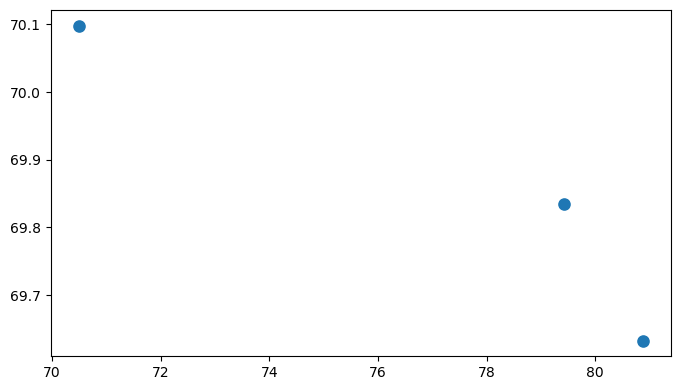

In [10]:
# The same plot axes allow a direct comparison of the two link types.
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter([r['elevation_deg'] for r in gps_results],
           [1000*r['tau_s'] for r in gps_results],
           label='GPS G21 -> DYNG', s=65)
ax.scatter([r['elevation_deg'] for r in doris_results],
           [1000*r['tau_s'] for r in doris_results],
           label='DIOB -> Sentinel-6A', marker='s', s=65)
ax.set(xlabel='Elevation [degrees]', ylabel='Vacuum signal flight time [ms]',
       title='Flight time from real SP3 positions, 1 January 2024')
ax.grid(alpha=.3)
ax.legend()
plt.show()

# Use separate vertical scales to show GPS and DORIS range corrections clearly.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, results, label in [
    (axes[0], gps_results, 'GPS downlink'),
    (axes[1], doris_results, 'DORIS uplink'),
]:
    ax.plot([r['elevation_deg'] for r in results],
            [r['light_time_m'] for r in results], 'o-')
    ax.axhline(0., color='gray', lw=1)
    ax.set(xlabel='Elevation [degrees]',
           ylabel='Corrected minus naive range [m]', title=label)
    ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

## 7. Link to Doppler and positioning

For GPS code positioning, the **light-time-corrected geometric range** is one contribution to the predicted pseudorange. Satellite clock and other corrections will be added in the later positioning notebook.

For DORIS Doppler, the signal is emitted by the beacon and received by the LEO. Doppler depends on the **change in range with time**, not simply the range at one epoch. The next cell shows the change in the *geometric light-time correction* over the selected pass. It is **not** a complete Doppler frequency or range-rate prediction.

In [ ]:
# Finite difference of the DORIS light-time range correction (m/s).
# This is a geometric illustration only, not a measured Doppler residual.
for earlier, later in zip(doris_results[:-1], doris_results[1:]):
    dt = (later['epoch'] - earlier['epoch']).total_seconds()
    delta_rate = (later['light_time_m'] - earlier['light_time_m']) / dt
    print(f'{earlier["epoch"]:%H:%M:%S} to {later["epoch"]:%H:%M:%S}: '
          f'Δ(light-time range correction)/Δt = {delta_rate:+.6f} m/s')

## 8. Summary / questions for students

* We **do not** use a satellite's reception-time position in a GPS downlink; it transmits earlier.
* We **do** use Sentinel-6A's reception-time position in a DORIS uplink; its ground beacon transmits earlier.
* Converting both positions to a common reference frame matters because Earth rotates during flight.
* A vacuum flight time of \(\tau\) is **not the same** as a range *correction* of \(c\tau\).
* This lesson uses **real SP3 orbits and station coordinates**, but the selected epochs are SP3 sample epochs—not necessarily epochs of an actual recorded GNSS or DORIS measurement.

**Think about it:** Why might the GPS range correction change sign? Why is it wrong to evaluate the Sentinel-6A receiver position at \(t_e\) rather than at \(t_r\)? What additional steps are needed to turn the DORIS ranges into predicted Doppler observations?

**Next:** introduce satellite/receiver clocks and measured code/Doppler, then atmospheric delays and biases. Those are intentionally excluded here.